# 03 · Evaluation

Final evaluation of the chosen model (**v2**), with v0, v1 and the mean-shape baseline as reference points.

| Model | What it is |
|---|---|
| mean-shape baseline | The average training face, placed in every image's 224×224 crop |
| v0 | The model submitted to the Nanodegree (trained with the input-scaling bug) |
| v1 | The v0 architecture retrained with correct inputs |
| v2 | Compact head with BatchNorm + augmentation + Wing loss; chosen on validation in notebook 02 |

The headline numbers come from the **holdout split**: 15 % of the people in the training CSV, never used for training, model selection or any other decision. This notebook evaluates it once, and the results are reported as they came out.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import metrics
from data_load import identity_of, read_rgb, split_by_identity
from models import load_trained

train_df, val_df, holdout_df = split_by_identity(pd.read_csv(config.TRAIN_CSV),
                                                 config.SPLIT_FRACTIONS, config.SPLIT_SEED)
test_df = pd.read_csv(config.TEST_CSV)
for name, df in [("train", train_df), ("validation", val_df), ("holdout", holdout_df), ("official test", test_df)]:
    print(f"{name:13s}: {len(df):4d} images, {df.iloc[:, 0].map(identity_of).nunique()} people")

nets = {"v0 (submitted)": load_trained(config.V0_WEIGHTS),
        "v1": load_trained(config.V1_WEIGHTS),
        "v2 (final)": load_trained(config.FINAL_WEIGHTS)}
mean_shape = metrics.fit_mean_shape(train_df, config.TRAIN_DIR)


def predict_all(frame, root):
    preds = {"mean-shape baseline": metrics.predict_mean_shape(mean_shape, frame, root)}
    for name, net in nets.items():
        preds[name] = metrics.predict_frame(net, frame, root)
    return preds


def summary_table(preds, gt):
    return pd.DataFrame({name: metrics.summary(p, gt) for name, p in preds.items()}).T.round(2)

train        : 2409 images, 243 people
validation   :  528 images, 52 people
holdout      :  525 images, 52 people
official test:  770 images, 347 people


## What went wrong with the submitted model (v0)

**What happened.**
- All dataset images are RGBA PNGs saved with a `.jpg` extension. The starter code read them with `matplotlib.image.imread`. Since matplotlib 3.3 (July 2020), that function recognizes the PNG content regardless of the extension and returns `float32` in [0, 1].
- The `Normalize` transform then divided by 255 again. v0 was trained on images in **[0, 0.004]**: nearly black, with almost no contrast.
- Gradient descent took the easy way out: the network ignored its input and learned to output **the average face**. In the original notebooks this was easy to miss, because the dataset faces are centered and roughly the same size, so the average face lands in roughly the right place on any single example.

**How it was found.**
1. After rebuilding the pipeline locally, the first quantitative check showed that v0's error on *its own training images* was the same as the mean-shape baseline: 13.5 px for both.
2. v0's predictions barely vary between images. Their spread is ~0.001 px, against ~15 px for the ground truth (see the cell below).
3. Tracing the input back showed values in [0, 0.004]. The cause was the PNG files with a `.jpg` extension combined with `imread`. In matplotlib ≤ 3.2, `imread` chose the reader from the file *extension* and returned these files as `uint8`, so the starter code was correct when it was written. In ≥ 3.3, it detects the content and returns floats. This was verified in the source of matplotlib 3.2.2, 3.3.0 and 3.7.1.
4. **It also happened in the original run, not only locally:**
   - The training loss logged on the Udacity workspace (figure below) is ~0.19 from the first epoch to the last. That is exactly the MSE of always predicting the mean shape (0.190).
   - The original filter notebook printed matplotlib's warning `Clipping input data to the valid range for imshow with RGB data ([0..1] for floats ...)`, which only appears when the image was read as floats.

**Why it went unnoticed.** `imshow` auto-scales grayscale images, so the nearly black inputs looked normal when plotted. The predictions looked plausible on a handful of centered faces. And there was no baseline and no quantitative metric to compare against.

**How it was fixed.**
- `data_load.read_rgb` reads every image as `uint8` RGB, so `Normalize` produces [0, 1].
- v1 and v2 were trained on correctly scaled inputs.
- v0 is still evaluated here, under the conditions it was trained with (`input_scale = 1/255`), so its numbers reflect what it learned and not an extra train/test mismatch.

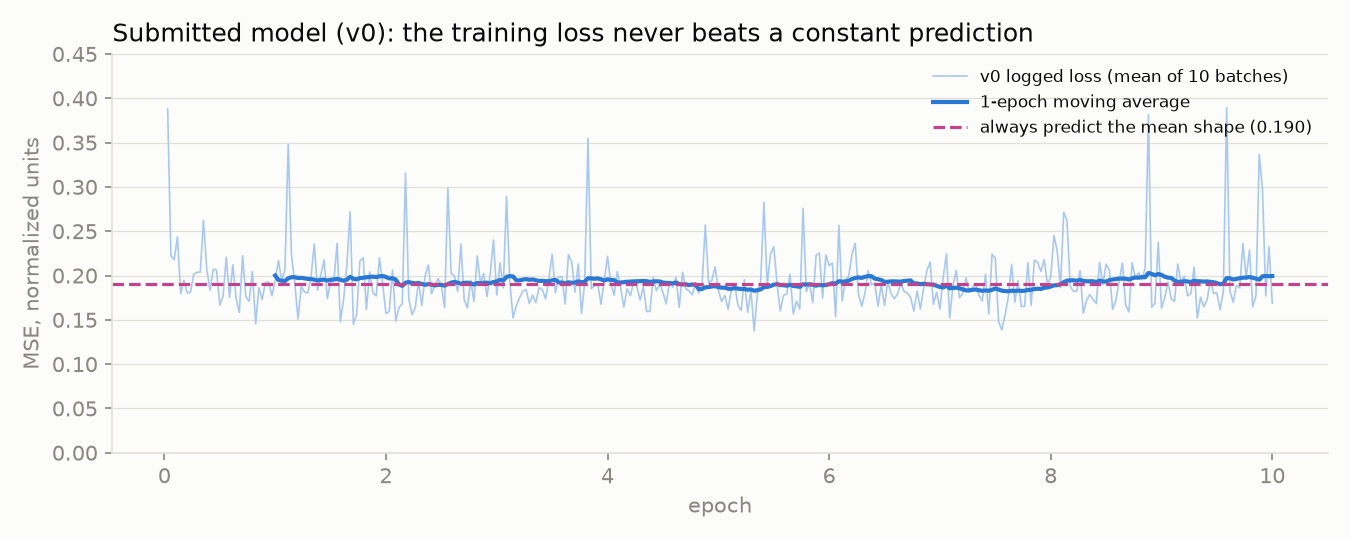

In [2]:
display(Image(filename=str(config.ASSETS_DIR / "v0_loss_plateau.png")))

In [3]:
# Do v0's predictions depend on the input at all? Compare the spread across holdout images.
gt_holdout = metrics.ground_truth(holdout_df)
holdout_preds = predict_all(holdout_df, config.TRAIN_DIR)


def spread_224(pts, frame):
    # spread of the points across images, in the 224×224 network frame
    maps = metrics._frame_maps(frame, config.TRAIN_DIR)
    local = np.stack([p * s - o for p, (o, s) in zip(pts, maps)])
    return local.std(axis=0).mean()


print(f"ground truth: {spread_224(gt_holdout, holdout_df):6.2f} px")
for name in nets:
    print(f"{name:15s}: {spread_224(holdout_preds[name], holdout_df):6.2f} px")

ground truth:  15.13 px


v0 (submitted) :   0.00 px


v1             :  13.09 px


v2 (final)     :  12.82 px


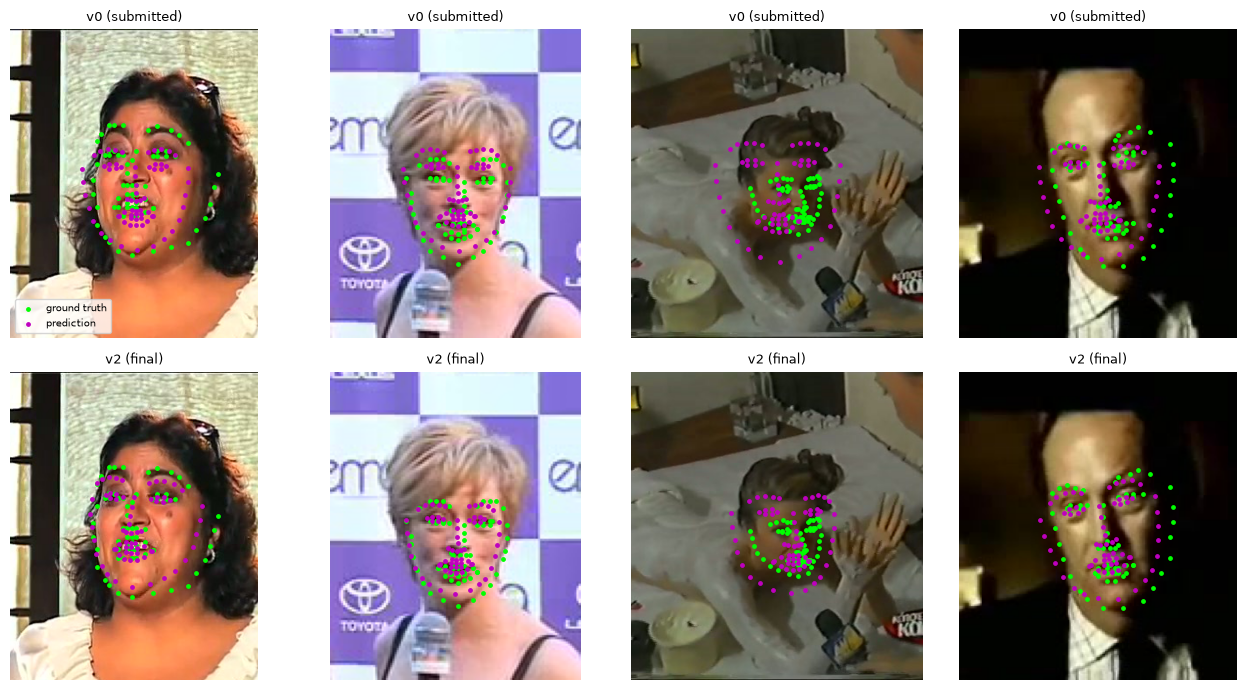

In [4]:
rng = np.random.default_rng(1)
idx = rng.choice(len(holdout_df), 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for j, i in enumerate(idx):
    image = read_rgb(config.TRAIN_DIR / holdout_df.iloc[i, 0])
    for row, name in enumerate(["v0 (submitted)", "v2 (final)"]):
        ax = axes[row, j]
        ax.imshow(image)
        ax.scatter(*gt_holdout[i].T, s=6, c="lime", label="ground truth")
        ax.scatter(*holdout_preds[name][i].T, s=6, c="m", label="prediction")
        ax.set_title(name, fontsize=9)
        ax.axis("off")
axes[0, 0].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

## Holdout: unseen people (headline result)

525 images of 52 people that no model selection step ever looked at. v0 is the exception: it was trained on the full training CSV, so these people were in *its* training data.

In [5]:
holdout_table = summary_table(holdout_preds, gt_holdout)
holdout_table

,mean_px,median_px,nme_%,median_nme_%,failure_rate_%(nme>0.10)
mean-shape baseline,14.48,11.60,32.42,24.98,97.14
v0 (submitted),14.60,11.89,32.56,25.12,96.76
v1,6.49,5.32,15.15,10.83,56.57
v2 (final),5.18,4.23,12.08,9.04,39.05


In [6]:
# The same metrics on validation, where v2 was chosen
val_preds = predict_all(val_df, config.TRAIN_DIR)
gt_val = metrics.ground_truth(val_df)
compare = pd.DataFrame({"validation": summary_table(val_preds, gt_val).loc["v2 (final)"],
                        "holdout": holdout_table.loc["v2 (final)"]})
compare

,validation,holdout
mean_px,5.18,5.18
median_px,4.28,4.23
nme_%,11.52,12.08
median_nme_%,9.44,9.04
failure_rate_%(nme>0.10),43.75,39.05


,jaw NME %,eyebrows NME %,nose NME %,eyes NME %,mouth NME %
mean-shape baseline,33.1,33.6,33.1,30.4,32.2
v0 (submitted),33.3,33.5,33.2,30.4,32.4
v1,17.4,16.0,13.9,13.6,14.3
v2 (final),15.1,12.4,10.9,10.4,10.9


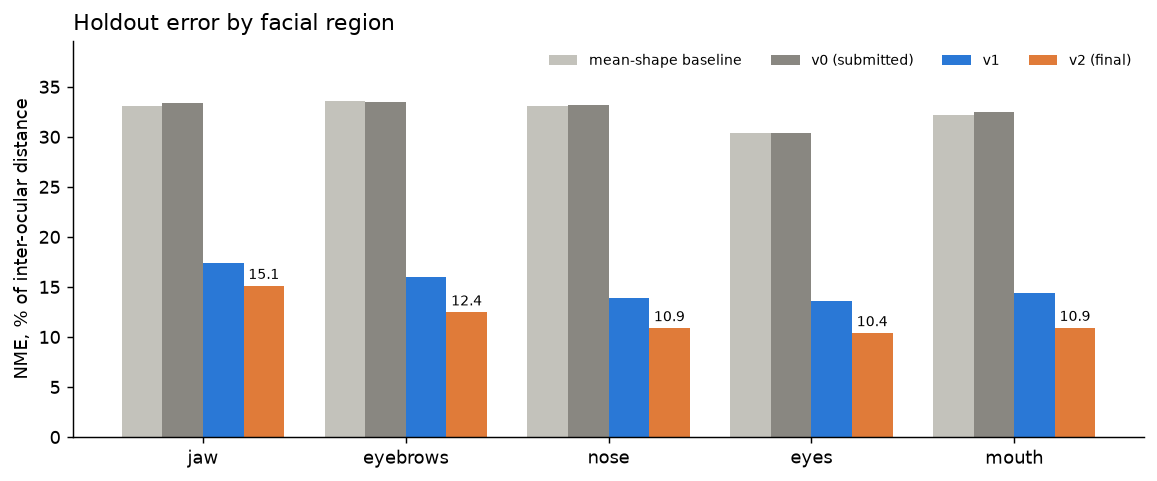

In [7]:
regions = pd.DataFrame({name: metrics.region_nme(p, gt_holdout) for name, p in holdout_preds.items()}).T
display(regions.round(1).rename(columns=lambda c: f"{c} NME %"))

colors = {"mean-shape baseline": "#c3c2bb", "v0 (submitted)": "#898781", "v1": "#2a78d6", "v2 (final)": "#e07b39"}
fig, ax = plt.subplots(figsize=(9, 3.8), dpi=130)
width = 0.2
x = np.arange(len(regions.columns))
for k, name in enumerate(regions.index):
    bars = ax.bar(x + (k - 1.5) * width, regions.loc[name], width, color=colors[name], label=name)
    if name == "v2 (final)":
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
ax.set_xticks(x, regions.columns)
ax.set_ylabel("NME, % of inter-ocular distance")
ax.set_title("Holdout error by facial region", loc="left")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, regions.values.max() * 1.18)
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "error_by_region.png", bbox_inches="tight")
plt.show()

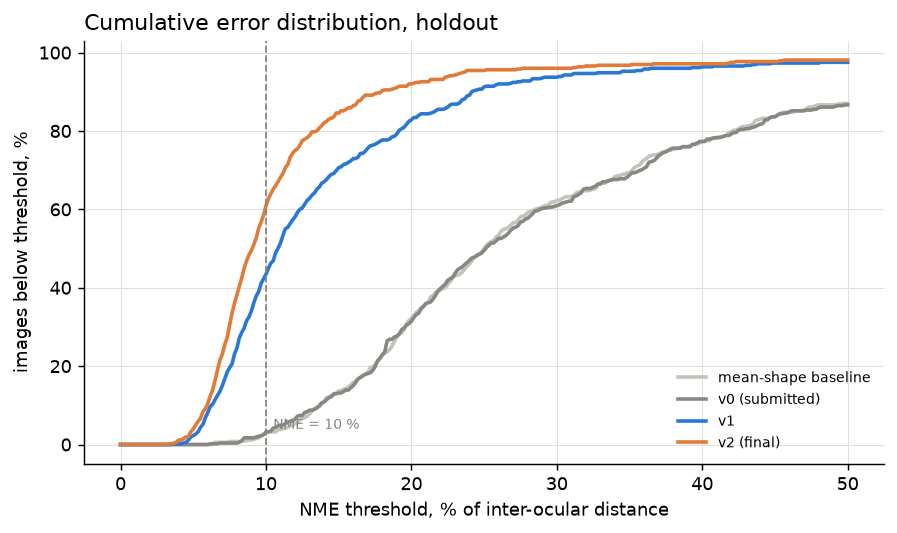

mean-shape baseline  images with NME < 10 %:   2.9%   < 20 %:  32.2%
v0 (submitted)       images with NME < 10 %:   3.2%   < 20 %:  31.4%
v1                   images with NME < 10 %:  43.4%   < 20 %:  82.9%
v2 (final)           images with NME < 10 %:  61.0%   < 20 %:  92.0%


In [8]:
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=130)
for name, p in holdout_preds.items():
    t, frac = metrics.ced(metrics.nme(p, gt_holdout), max_nme=0.5)
    ax.plot(100 * t, 100 * frac, color=colors[name], linewidth=2, label=name)
ax.axvline(10, color="#898781", linestyle="--", linewidth=1)
ax.text(10.5, 4, "NME = 10 %", color="#898781", fontsize=8)
ax.set_xlabel("NME threshold, % of inter-ocular distance")
ax.set_ylabel("images below threshold, %")
ax.set_title("Cumulative error distribution, holdout", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e1e0d9", linewidth=0.6)
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "ced_curve.png", bbox_inches="tight")
plt.show()
for name, p in holdout_preds.items():
    n = metrics.nme(p, gt_holdout)
    print(f"{name:20s} images with NME < 10 %: {100 * (n < 0.10).mean():5.1f}%   < 20 %: {100 * (n < 0.20).mean():5.1f}%")

**Holdout results.**
- **v2: 5.2 px mean error, 12.1 % NME, 9.0 % median NME.** 61 % of the holdout images are below NME 10 % and 92 % below 20 %.
- **Slightly worse than on validation.** NME is 12.1 % against 11.5 %, while the mean pixel error is the same (5.18 px) and the median NME is a little better. Both splits are only 52 people each, so a difference of this size is within the variation between two small sets of people. The holdout number is the one to quote.
- **The ranking from validation holds.** v2 beats v1 (15.2 % NME) in every region, and both are far below the baseline (32.4 %). v0 is indistinguishable from the baseline even though it trained on these people.
- **By region,** the jaw remains the hardest for v2 (15.1 %), and eyes, nose and mouth are the easiest (~10.5–11 %).

## Official test set (with a caveat)

The 770 labelled test images come from **the same video clips** as the training images (notebook 01): neighboring frames, the same framing, the same people. Errors on this set are optimistic for any model trained on the full training CSV. They are reported for completeness and comparability with the original project, not as an estimate of performance on new faces.

In [9]:
gt_test = metrics.ground_truth(test_df)
test_preds = predict_all(test_df, config.TEST_DIR)
summary_table(test_preds, gt_test)

,mean_px,median_px,nme_%,median_nme_%,failure_rate_%(nme>0.10)
mean-shape baseline,12.73,10.85,28.49,23.70,97.01
v0 (submitted),12.83,10.99,28.64,23.77,96.49
v1,4.72,4.02,10.61,8.81,36.75
v2 (final),4.32,3.69,9.64,8.27,30.91


### Seen vs. unseen people

v1 and v2 were trained on 70 % of the people, so the official test set can be split by whether each person was in their training subset:

- **seen:** train-split people. Neighboring frames of clips the model trained on.
- **unseen (validation):** people used for model selection but not for fitting the weights.
- **unseen (holdout):** people never used for anything.

v0 trained on everyone, so for v0 all three groups are "seen".

In [10]:
group_of = {}
for group, df in [("seen (train split)", train_df), ("unseen (validation)", val_df), ("unseen (holdout)", holdout_df)]:
    group_of.update({p: group for p in df.iloc[:, 0].map(identity_of)})
groups = test_df.iloc[:, 0].map(identity_of).map(group_of)

rows = {}
for group in ["seen (train split)", "unseen (validation)", "unseen (holdout)"]:
    mask = (groups == group).to_numpy()
    rows[(group, "images")] = mask.sum()
    for name, p in test_preds.items():
        rows[(group, name)] = 100 * metrics.nme(p[mask], gt_test[mask]).mean()
split_table = pd.Series(rows).unstack(0)[["seen (train split)", "unseen (validation)", "unseen (holdout)"]]
split_table = split_table.loc[["images", "mean-shape baseline", "v0 (submitted)", "v1", "v2 (final)"]]
split_table.round(1)

,seen (train split),unseen (validation),unseen (holdout)
images,534.0,120.0,116.0
mean-shape baseline,27.7,30.1,30.7
v0 (submitted),27.8,30.4,30.8
v1,9.5,12.7,13.8
v2 (final),9.3,10.0,10.8


**Official test results.**
- **The official test set flatters every trained model.** v2 gets 9.6 % NME there, against 12.1 % on the holdout. The split above shows why: frames from people a model trained on are easier.
- **v2 generalizes better than v1.** v1's error goes from 9.5 % on seen people to 13.8 % on holdout people, a gap of 4.3 points. v2 goes from 9.3 % to 10.8 %, a gap of 1.5 points. That fits v2's design (augmentation and 8.6× fewer parameters): it memorizes less of the people it saw. Each unseen group has only ~120 images, so the exact gaps are noisy, but the direction is clear.
- **v0 and the baseline are flat across groups,** as expected for a constant prediction.

## Qualitative results

### Random holdout samples (not cherry-picked)

Eight holdout images drawn with a fixed seed. Green = ground truth, magenta = v2.

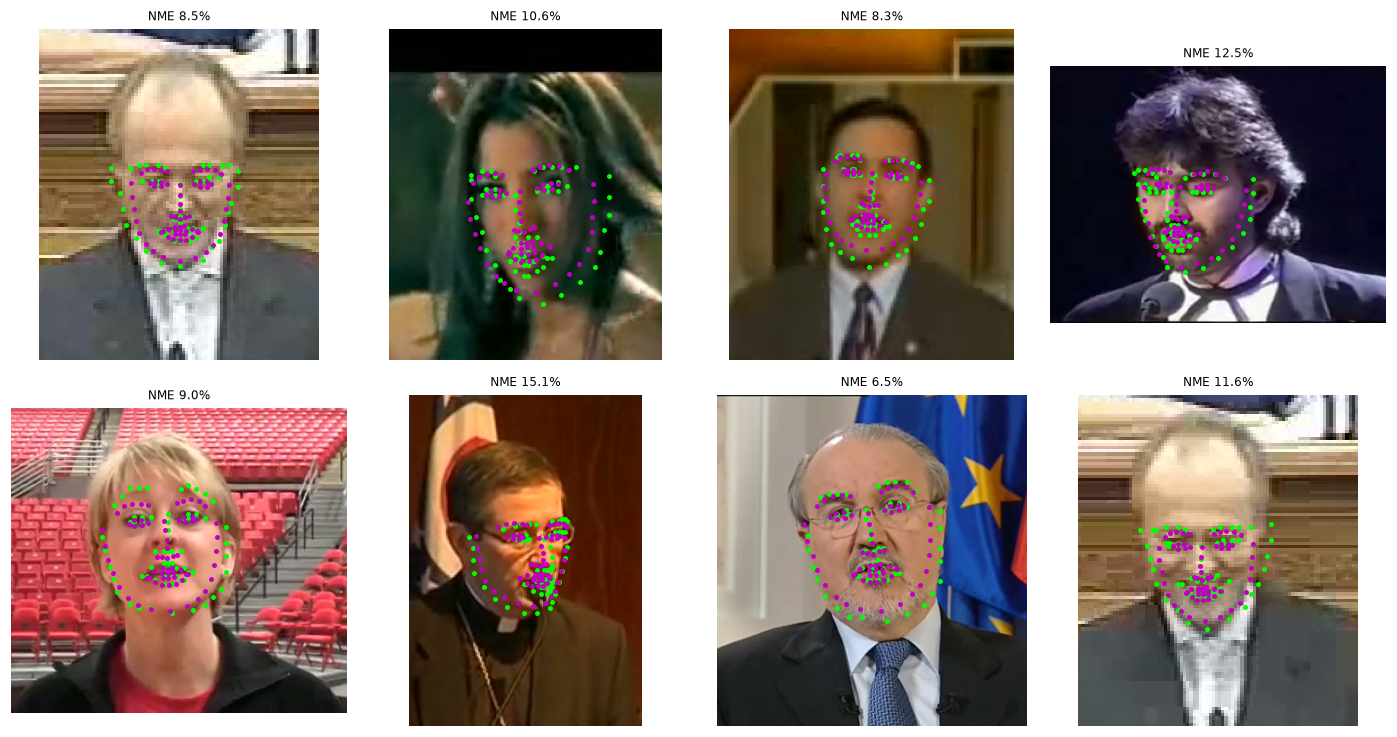

In [11]:
def show_predictions(indices, preds, title_fn, path=None, ncols=4):
    nrows = int(np.ceil(len(indices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows), dpi=110)
    for ax, i in zip(axes.flat, indices):
        image = read_rgb(config.TRAIN_DIR / holdout_df.iloc[i, 0])
        ax.imshow(image)
        ax.scatter(*gt_holdout[i].T, s=5, c="lime")
        ax.scatter(*preds[i].T, s=5, c="m")
        ax.set_title(title_fn(i), fontsize=8)
        ax.axis("off")
    for ax in axes.flat[len(indices):]:
        ax.axis("off")
    fig.tight_layout()
    if path:
        fig.savefig(path, bbox_inches="tight")
    plt.show()


v2_pred = holdout_preds["v2 (final)"]
v2_nme = metrics.nme(v2_pred, gt_holdout)
sample = np.random.default_rng(42).choice(len(holdout_df), 8, replace=False)
show_predictions(sample, v2_pred, lambda i: f"NME {100 * v2_nme[i]:.1f}%",
                 config.ASSETS_DIR / "holdout_samples.png")

### Best and worst holdout predictions

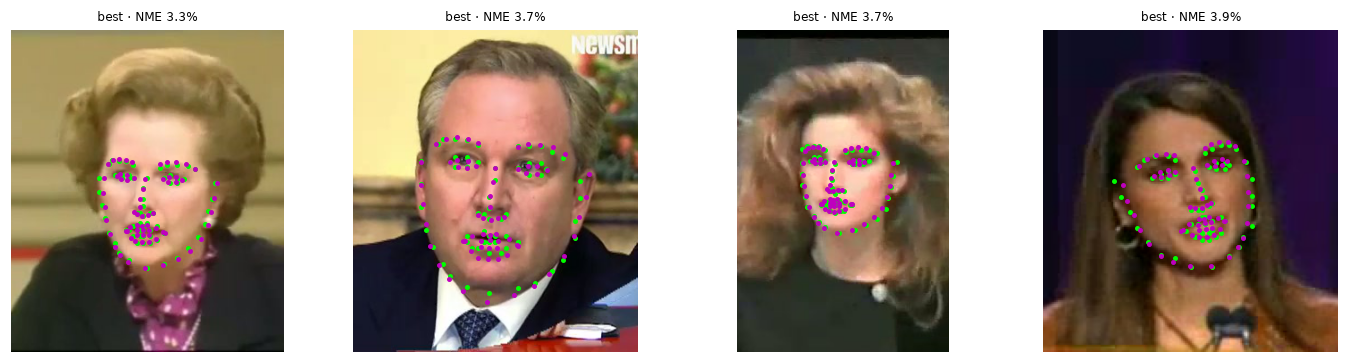

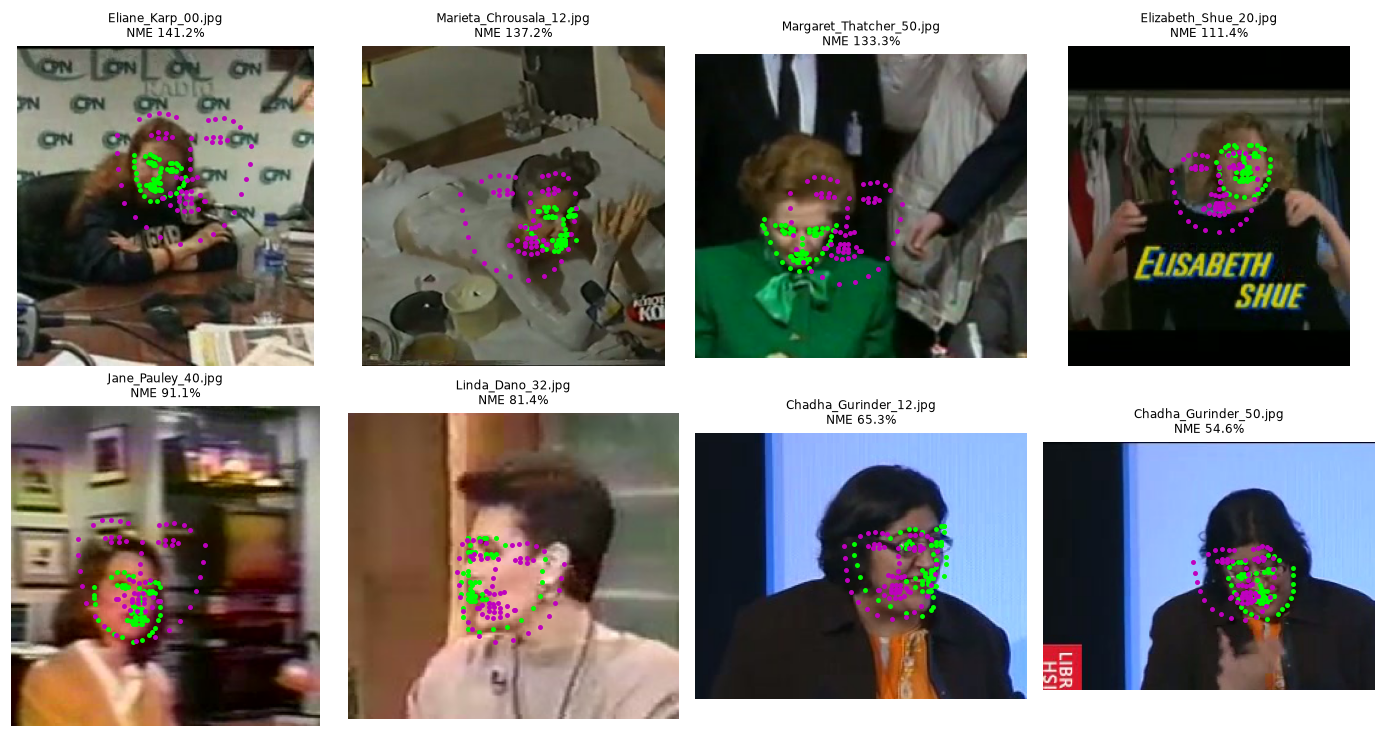

In [12]:
order = np.argsort(v2_nme)
best, worst = order[:4], order[::-1][:8]
show_predictions(best, v2_pred, lambda i: f"best · NME {100 * v2_nme[i]:.1f}%")
show_predictions(worst, v2_pred, lambda i: f"{holdout_df.iloc[i, 0]}\nNME {100 * v2_nme[i]:.1f}%")

# Figure for the README: 3 best + 3 worst
fig, axes = plt.subplots(2, 3, figsize=(10, 7), dpi=110)
for row, (label, idxs) in enumerate([("best", best[:3]), ("worst", worst[:3])]):
    for ax, i in zip(axes[row], idxs):
        ax.imshow(read_rgb(config.TRAIN_DIR / holdout_df.iloc[i, 0]))
        ax.scatter(*gt_holdout[i].T, s=5, c="lime")
        ax.scatter(*v2_pred[i].T, s=5, c="m")
        ax.set_title(f"{label} · NME {100 * v2_nme[i]:.1f}%", fontsize=9)
        ax.axis("off")
fig.tight_layout()
fig.savefig(config.ASSETS_DIR / "best_worst.png", bbox_inches="tight")
plt.close(fig)

In [13]:
# Where does the error concentrate in the worst 10 % of holdout images?
worst_decile = order[::-1][: len(order) // 10]
err = metrics.point_errors(v2_pred, gt_holdout) / metrics.interocular(gt_holdout)[:, None]
by_region = pd.DataFrame({
    "worst 10 %": {r: 100 * err[np.ix_(worst_decile, list(ix))].mean() for r, ix in config.REGIONS.items()},
    "all holdout": {r: 100 * err[:, list(ix)].mean() for r, ix in config.REGIONS.items()},
}).T.round(1)
by_region

,jaw,eyebrows,nose,eyes,mouth
worst 10 %,41.9,40.7,38.2,36.6,36.2
all holdout,15.1,12.4,10.9,10.4,10.9


In [14]:
# Does error grow for small faces (low inter-ocular distance)?
iod = metrics.interocular(gt_holdout)
bins = pd.qcut(iod, 4)
pd.DataFrame({"inter-ocular px": bins, "v2 NME %": 100 * v2_nme, "v2 mean px": metrics.point_errors(v2_pred, gt_holdout).mean(1)}) \
    .groupby("inter-ocular px", observed=True).mean().round(1)

,v2 NME %,v2 mean px
inter-ocular px,,
"(11.044, 32.558]",17.9,4.6
"(32.558, 43.012]",11.9,4.6
"(43.012, 61.008]",9.4,4.8
"(61.008, 130.138]",9.1,6.7


**What goes wrong.**
- **Failures are whole-face misplacements, not one bad region.** In the worst 10 % of holdout images the error is high everywhere (36–42 % NME in every region).
- **Wide, off-center shots.** Five of the eight worst images (Eliane Karp, Marieta Chrousala, Margaret Thatcher, Elizabeth Shue, Jane Pauley) are wide shots where the face is small and away from the center. The model predicts a normally sized face near the middle of the image. It has learned the dataset's typical framing as a prior. In the detection pipeline (notebook 04) the face crop comes from a detector, which removes most of this failure mode.
- **Strong head turns** (Linda Dano, Chadha Gurinder). The predicted shape stays closer to a frontal face than the real one. The same pull toward frontal shows up more mildly in the random samples, for example on the turned head with an NME of 15.1 %.
- **Small faces** have a higher NME (17.9 % for the smallest quarter by inter-ocular distance, against ~9 % for the rest), but their *pixel* error stays about the same (~4.6 px). Part of the higher NME is simply dividing a similar pixel error by a small inter-ocular distance. Turned heads also have a short inter-ocular distance.

## Summary

| | Holdout NME | Holdout mean error | Params |
|---|---|---|---|
| Mean-shape baseline | 32.4 % | 14.5 px | – |
| v0 (submitted) | 32.6 % | 14.6 px | 44.5 M |
| v1 (v0 architecture, inputs fixed) | 15.2 % | 6.5 px | 44.5 M |
| **v2 (final)** | **12.1 %** | **5.2 px** | **5.2 M** |

- The submitted model learned a constant because of a double normalization. Fixing it more than halves the error with the same architecture.
- v2 (compact head + augmentation + Wing loss) adds another 3 points of NME, generalizes better to unseen people and is 8.6× smaller. Its three changes were evaluated together, and an ablation is listed as a next step.
- The official test set shares clips with the training data and overstates accuracy: 9.6 % against 12.1 % NME for v2.
- **These NME values are not comparable with benchmarks such as 300W.** The faces here are much smaller (median inter-ocular distance ~44 px), the images come from low-quality video frames, the annotations have their own conventions, and the normalization (outer eye corners) and protocol differ.